# Path A, P25 — the final model: L1 + L1b + L3 (Oct 30, 2026)

**Spec (pre-registered; as given, not changed after seeing results):**

TASK: P25, the final model (pre-registered: L1 + L1b + L3, one round). Never load Ring/CT. No retuning; nothing changes after results.

0. Descriptive table (light, from p24_checks.csv), for every L1 statistic: sim mean, human value and CI; direction (high/low); gap in CI half-widths. Save results/tables/p24_directions.csv and print it. Descriptive only.
1. Fit L1b (pre-registered). Mid-round halts are a two-type mixture.
   - Per interface (lab v09, old CL, CC), on the same G-train halt spells as P17 (the F1b version of motion.py). Resume = event; reversal or round end = censored.
   - Fit by maximum likelihood a discrete-time mixture of geometric durations in ticks: P(halt > n ticks) = p(1 - q_f)^n + (1 - p)(1 - q_s)^n.
   - Report p, q_f, q_s (and lam = q/dt), with group-bootstrap 95% CIs (1,000 resamples, stratified by dataset, seed 573).
   - Figure: KM survival vs. the fitted curve.
   - Start delays stay one constant rate (lam_start).
2. Fit sigma_g (pre-registered, L3). On the G-train hazard table: logit h = (frozen M2' linear predictor, as an offset) + u_g, u_g ~ N(0, sigma_g^2), one u per group.
   - Marginal maximum likelihood via Gauss-Hermite (>= 30 nodes).
   - Report sigma_g with a profile-likelihood 95% CI. The M2' weights do not change.
3. Simulator
   - L1b: when a mid-round halt starts, draw its type (fast with probability p); resume per tick with q_f or q_s. The reversal hazard still runs while halted.
   - L3: in each replicate, each simulated group copy draws u_g ~ N(0, sigma_g^2) once. It is added to logit h for every player in every round of that group.
   - Preset "final" = L1 + L1b + L3. Leave L1 unchanged.
   - Tests: unit tests for both; exactly the old behavior when p = 1 (one type) and sigma_g = 0.
4. Build check (recovery)
   - Simulate "final" on the G6train design, R = 2, seed 573.
   - Re-estimate the L1b parameters with step 1's code and sigma_g with step 2's code. PASS: each within its 95% CI.
   - Confirm the M2' lab-v09 refit still passes 6/6.
   - If anything fails: diagnose and propose; don't fix.
5. Run scripts: preset "final" in scripts/p24_main.py (seed 4001) and p24_checks.py (reported next to L1; no triggers for final).

**Implementation choices (made before any P25 result):**
- Halt length in ticks n = max(1, round(duration / dt)), dt = the round's tick (CC halt lengths are not whole ticks: the cloud logger's row times jitter). A resume after n ticks has likelihood S(n - 1) - S(n), a censored halt S(n), so with one type the estimate is resumes / halt ticks, P17's estimator. Censored: every exit but resume (reversal, round end, and also probe and unresolved, as in P17's lam_resume). Fast = the type with the larger q. lam = q / dt with dt = the mean tick of the interface's halts (descriptive; the simulator uses q per tick).
- sigma_g: adaptive Gauss-Hermite, 30 nodes per group, centred at the mode of each group's integrand and scaled by its curvature (as lme4's nAGQ). Groups have thousands of bins, so the integrand is much narrower than sigma and fixed nodes would miss it; 30 and 60 nodes agree to 1e-6. The profile likelihood of the only parameter is the marginal likelihood itself; CI = {sigma : 2 (l_max - l(sigma)) <= 3.841}.
- Simulator: the L3 u values come from a stream spawned after the round streams, so the rounds' own draws do not change; with p = 1 (or 0) no halt type is drawn.

Code: `src/slider/halts.py`, `src/slider/frailty.py`, `src/slider/sim.py` (motion "L1b", offset, preset "final"), `src/slider/design.py` (group offsets); tests `tests/test_final.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from slider import config, design, fit, frailty, halts, hazard, motion, sim
from slider.stats import kaplan_meier

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 220)

## 0. Descriptive table (L1 vs human; descriptive only)

`scripts/p24_directions.py` → `results/tables/p24_directions.csv`. gap_hw = (sim mean − human) / CI half-width.

In [2]:
directions = pd.read_csv(config.P24_DIRECTIONS)
with pd.option_context("display.max_rows", 100, "display.float_format", "{:.4g}".format):
    display(directions.drop(columns="in_check_list"))

,target,stat,topology,dataset,sim_mean,human,ci_lo,ci_hi,ci_rule,verdict,direction,gap_hw
0,1,success_rate_pct,Full,CC,57.49,97.22,90.9,100,NaN,miss,low,-8.735
1,1,success_rate_pct,Full,CL,40.31,82.54,69.84,92.06,NaN,miss,low,-3.801
2,1,success_rate_pct,Hierarchy,CC,83.44,92.5,84.21,100,NaN,miss,low,-1.148
3,1,success_rate_pct,Hierarchy,CL,63.06,95.08,89.47,100,NaN,miss,low,-6.085
4,1,success_rate_pct,Hierarchy,EL,86.75,94.12,88.24,100,NaN,miss,low,-1.253
5,1,success_rate_pct,Star,CC,98.38,100,90.97,100,Clopper-Pearson,pass,low,-0.358
6,2,consensus_time_km_median_s,Full,CC,142,45.99,32.72,59.95,NaN,miss,high,7.053
7,2,consensus_time_km_median_s,Full,CL,299.4,89.19,71.09,118.7,NaN,miss,high,8.831
8,2,consensus_time_km_median_s,Hierarchy,CC,66.36,35.33,22.02,48.02,NaN,miss,high,2.386
9,2,consensus_time_km_median_s,Hierarchy,CL,181.3,47.06,36.84,67.74,NaN,miss,high,8.689


## 1. L1b: two-type halt mixture per interface (G-train)

G-train halt spells (`load_runs("behavior")`, the P17 set), maximum likelihood, 1,000 group-bootstrap resamples stratified by dataset, seed 573 → `results/tables/p25_halts.csv`.

In [3]:
h = halts.load_halts()                                          # the P17 halt spells, with n (ticks) and event
print(len(h), "halts;", h.groupby("interface")["file"].nunique().to_dict(), "groups;", h["exit"].value_counts().to_dict())
fits = halts.fit_table(h)                                       # about 3 minutes (3 x 1,000 bootstrap fits)
fits.to_csv(config.P25_HALTS, index=False)
fits.round(4)

32263 halts; {'cc': 17, 'lab_v09': 20, 'old_cl': 2} groups; {'resume': 29859, 'reversal': 2001, 'probe': 393, 'round_end': 9, 'unresolved': 1}


,interface,parameter,estimate,ci_low,ci_high,halts,resumes,groups,dt,loglik,loglik_one_type,converged
0,lab_v09,p,0.9152,0.8912,0.9304,12434,11273,20,0.1008,-26440.5502,-29953.7491,True
1,lab_v09,q_f,0.3053,0.2825,0.3427,12434,11273,20,0.1008,-26440.5502,-29953.7491,True
2,lab_v09,q_s,0.0184,0.0104,0.0295,12434,11273,20,0.1008,-26440.5502,-29953.7491,True
3,lab_v09,lam_f,3.0300,2.8038,3.4004,12434,11273,20,0.1008,-26440.5502,-29953.7491,True
4,lab_v09,lam_s,0.1823,0.1031,0.2930,12434,11273,20,0.1008,-26440.5502,-29953.7491,True
5,old_cl,p,0.8933,0.8795,0.9188,3575,3267,2,0.1000,-7612.4446,-8687.6362,True
6,old_cl,q_f,0.3333,0.3097,0.3827,3575,3267,2,0.1000,-7612.4446,-8687.6362,True
7,old_cl,q_s,0.0276,0.0262,0.0318,3575,3267,2,0.1000,-7612.4446,-8687.6362,True
8,old_cl,lam_f,3.3333,3.0968,3.8266,3575,3267,2,0.1000,-7612.4446,-8687.6362,True
9,old_cl,lam_s,0.2756,0.2617,0.3181,3575,3267,2,0.1000,-7612.4446,-8687.6362,True


Log-likelihood gain of two types over one (same halts):

In [4]:
gain = fits.drop_duplicates("interface")[["interface", "halts", "resumes", "groups", "dt", "loglik", "loglik_one_type"]]
gain.assign(gain=gain["loglik"] - gain["loglik_one_type"]).round(2)

,interface,halts,resumes,groups,dt,loglik,loglik_one_type,gain
0,lab_v09,12434,11273,20,0.10,-26440.55,-29953.75,3513.20
5,old_cl,3575,3267,2,0.10,-7612.44,-8687.64,1075.19
10,cc,16254,15319,17,0.03,-49173.39,-52959.40,3786.02


Figure: KM survival of the halt lengths (ticks; non-resume exits censored) and the fitted mixture S(n) (`results/figures/p25_halts.png`).

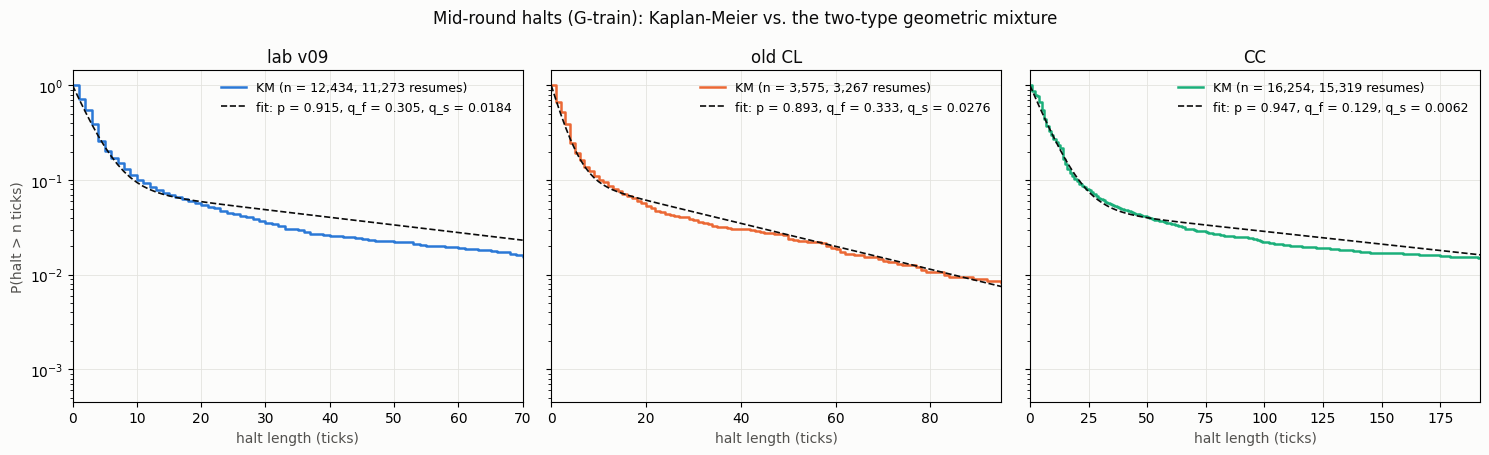

In [5]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COLORS = {"lab_v09": "#2a78d6", "old_cl": "#eb6834", "cc": "#1baf7a"}
NAMES = {"lab_v09": "lab v09", "old_cl": "old CL", "cc": "CC"}
est = fits.set_index(["interface", "parameter"])["estimate"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), facecolor=SURFACE, sharey=True)
for ax, name in zip(axes, motion.INTERFACES):
    x = h[h["interface"] == name]
    km, _ = kaplan_meier(x["n"], x["event"])
    ax.step(np.r_[0, km["time"]], np.r_[1, km["survival"]], where="post", color=COLORS[name], linewidth=1.8,
            label=f"KM (n = {len(x):,}, {int(x['event'].sum()):,} resumes)")
    nn = np.arange(0, int(np.percentile(x["n"], 99.5)) + 1)
    p, q_f, q_s = (est[(name, k)] for k in halts.PARAMS)
    ax.plot(nn, halts.survival(nn, p, q_f, q_s), color=INK, linewidth=1.2, linestyle="--",
            label=f"fit: p = {p:.3f}, q_f = {q_f:.3f}, q_s = {q_s:.4f}")
    ax.set_yscale("log")
    ax.set_xlim(0, nn[-1])
    ax.set_title(NAMES[name], color=INK)
    ax.set_xlabel("halt length (ticks)", color=INK_2)
    ax.grid(color=GRID, linewidth=0.6)
    ax.set_facecolor(SURFACE)
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("P(halt > n ticks)", color=INK_2)
fig.suptitle("Mid-round halts (G-train): Kaplan-Meier vs. the two-type geometric mixture", color=INK)
fig.tight_layout()
fig.savefig(config.P25_HALTS_FIGURE, dpi=150, facecolor=SURFACE)
plt.show()

## 2. L3: sigma_g of the group effect (G-train hazard table, M2' frozen as an offset)

→ `results/tables/p25_sigma.csv`.

In [6]:
ht_train = frailty.g_train()
eta, y, g = frailty.prepare(ht_train)
print("bins", len(y), "| reversals", int(y.sum()), "| sum h(eta)", round(float((1 / (1 + np.exp(-eta))).sum()), 1),
      "| groups", g.max() + 1)
print("nodes check at sigma = 0.25: 30 nodes", round(frailty.marginal_ll(0.25, eta, y, g, 30), 6),
      "| 60 nodes", round(frailty.marginal_ll(0.25, eta, y, g, 60), 6))
sig = frailty.fit_sigma(ht_train)                               # about 20 s
pd.DataFrame([sig]).to_csv(config.P25_SIGMA, index=False)
pd.DataFrame([sig])

bins 336073 | reversals 6073 | sum h(eta) 6073.0 | groups 39


nodes check at sigma = 0.25: 30 nodes -27629.246385 | 60 nodes -27629.246385


,sigma_g,ci_low,ci_high,loglik,loglik_sigma0,lr_stat,groups,bins,reversals,nodes
0,0.23769,0.185407,0.311666,-27629.174191,-27753.708944,249.069507,39,336073,6073,30


Profile log-likelihood (the dashed line is the 95% cut, l_max − 3.841 / 2):

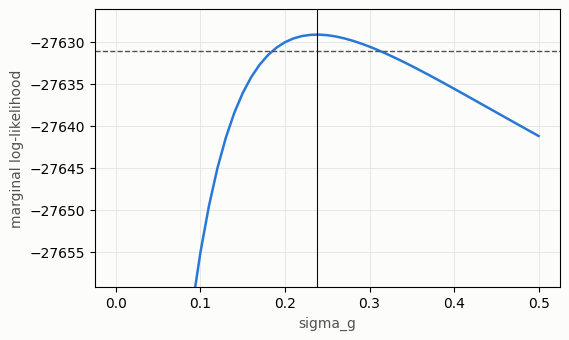

In [7]:
grid = np.linspace(0.0, 0.5, 51)
prof = [frailty.marginal_ll(s, eta, y, g) for s in grid]
fig, ax = plt.subplots(figsize=(6, 3.6), facecolor=SURFACE)
ax.plot(grid, prof, color=COLORS["lab_v09"], linewidth=1.8)
ax.axhline(sig["loglik"] - frailty.CHI2_95 / 2, color=INK_2, linestyle="--", linewidth=1)
ax.axvline(sig["sigma_g"], color=INK, linewidth=0.8)
ax.set_xlabel("sigma_g", color=INK_2); ax.set_ylabel("marginal log-likelihood", color=INK_2)
ax.set_ylim(sig["loglik"] - 30, sig["loglik"] + 3); ax.grid(color=GRID, linewidth=0.6); ax.set_facecolor(SURFACE)
plt.show()

## 4. Build check: "final" on G6train, R = 2, seed 573

Re-estimate with the same code: the L1b parameters (`halts.fit` on the simulated halts, per interface), sigma_g (`frailty.fit_sigma` on the simulated hazard table, one group per simulated group copy) and the M2' lab-v09-only refit (as in P23). PASS: L1b and sigma_g inside the step 1 / step 2 95% CIs; lab v09 weights within 2 SE of the true weights (6 of 6) → `results/tables/p25_recovery.csv`.

In [8]:
import time

FEATS = frailty.M2P
TRUE = sim.coefs("M2'")
G6 = design.design("G6train")
start = time.time()
rounds = design.simulate_rounds(G6, "final", R=2, seed=573)
u_drawn = pd.DataFrame([{"group": row.group, "copy": r, "u": out[r]["u"]}
                        for row, (out, _) in zip(G6.itertuples(), rounds) for r in range(2)]).drop_duplicates(["group", "copy"])
runs = [run for r in range(2) for run in design.copy_runs(G6, rounds, r, 573)]
ht_sim, dropped = hazard.build_hazard_table(runs, b=0.25, m=2)        # CC on the 0.1 s lab clock
h_sim = halts.add_ticks(motion.motion_table(runs)[1])
print(len(runs), "rounds |", len(ht_sim), "bins |", int(ht_sim["y_rev"].sum()), "reversals |",
      ht_sim["group_id"].nunique(), "group copies | drawn u: SD", round(u_drawn["u"].std(ddof=1), 4),
      f"| {(time.time() - start) / 60:.1f} min")

488 rounds | 1635400 bins | 44935 reversals | 78 group copies | drawn u: SD 0.2515 | 4.5 min


In [9]:
rows = []
for name in motion.INTERFACES:                                   # L1b
    r = halts.fit(*halts.counts(h_sim[h_sim["interface"] == name]))
    for k in halts.PARAMS:
        t = fits[(fits["interface"] == name) & (fits["parameter"] == k)].iloc[0]
        rows.append({"check": "L1b", "parameter": f"{name} {k}", "true": t["estimate"], "recovered": r[k],
                     "ci_low": t["ci_low"], "ci_high": t["ci_high"], "SE": np.nan,
                     "pass": t["ci_low"] <= r[k] <= t["ci_high"]})

s_sim = frailty.fit_sigma(ht_sim)                                 # L3
rows.append({"check": "L3", "parameter": "sigma_g", "true": sig["sigma_g"], "recovered": s_sim["sigma_g"],
             "ci_low": sig["ci_low"], "ci_high": sig["ci_high"], "SE": np.nan,
             "pass": sig["ci_low"] <= s_sim["sigma_g"] <= sig["ci_high"]})

v09 = ht_sim[ht_sim["interface"] == "lab_v09"]                    # M2' lab v09 only (P23)
X = fit.design(v09, FEATS, False).drop(columns="lab")             # lab = 1 on every lab v09 row
only = sm.Logit(v09["y_rev"].astype(float), X).fit(disp=0)
true09 = {**TRUE, "const": TRUE["const"] + TRUE["lab"]}
for term, b in only.params.items():
    se = only.bse[term]
    rows.append({"check": "M2' lab v09", "parameter": "const (+ lab)" if term == "const" else term, "true": true09[term],
                 "recovered": b, "ci_low": np.nan, "ci_high": np.nan, "SE": se, "pass": abs(b - true09[term]) <= 2 * se})
rec = pd.DataFrame(rows).assign(seed=573, R=2)
rec.to_csv(config.P25_RECOVERY, index=False)
with pd.option_context("display.float_format", "{:.4f}".format):
    display(rec)
for name, r in rec.groupby("check", sort=False):
    print(f"{name}: {int(r['pass'].sum())} of {len(r)} pass ({'PASS' if r['pass'].all() else 'FAIL'})")
print("sigma_g refit:", {k: round(v, 4) if isinstance(v, float) else v for k, v in s_sim.items()},
      "| converged:", bool(only.mle_retvals["converged"]))

,check,parameter,true,recovered,ci_low,ci_high,SE,pass,seed,R
0,L1b,lab_v09 p,0.9152,0.9119,0.8912,0.9304,NaN,True,573,2
1,L1b,lab_v09 q_f,0.3053,0.3058,0.2825,0.3427,NaN,True,573,2
2,L1b,lab_v09 q_s,0.0184,0.0177,0.0104,0.0295,NaN,True,573,2
3,L1b,old_cl p,0.8933,0.8926,0.8795,0.9188,NaN,True,573,2
4,L1b,old_cl q_f,0.3333,0.3321,0.3097,0.3827,NaN,True,573,2
5,L1b,old_cl q_s,0.0276,0.0342,0.0262,0.0318,NaN,False,573,2
6,L1b,cc p,0.9468,0.9459,0.9357,0.9595,NaN,True,573,2
7,L1b,cc q_f,0.1290,0.1303,0.1123,0.1452,NaN,True,573,2
8,L1b,cc q_s,0.0062,0.0064,0.0047,0.0080,NaN,True,573,2
9,L3,sigma_g,0.2377,0.2476,0.1854,0.3117,NaN,True,573,2


L1b: 8 of 9 pass (FAIL)
L3: 1 of 1 pass (PASS)
M2' lab v09: 3 of 6 pass (FAIL)
sigma_g refit: {'sigma_g': 0.2476, 'ci_low': 0.2119, 'ci_high': 0.2938, 'loglik': -187794.3022, 'loglik_sigma0': -189483.3865, 'lr_stat': 3378.1687, 'groups': 78, 'bins': 1635400, 'reversals': 44935, 'nodes': 30} | converged: True


### Build check result: L3 PASS (1/1), L1b 8 of 9 (old CL q_s misses), M2' lab v09 3 of 6 — diagnosed, not fixed

Diagnosis (`scripts/p25_diagnose.py`, run once; the same simulation, no code changed):

**M2' lab v09 (const, time_at_end_log1p, time_since_rev_log1p miss).** The refit is a plain logit with no group effect, while "final" now simulates one u_g per group copy. Groups with high u reverse more often, so their times since the last reversal / at the end are shorter: across the 40 lab-v09 copies, corr(u, mean log1p time_since_rev) = −0.74 and corr(u, mean log1p time_at_end) = −0.75. A plain logit then gives the time-since slopes spurious duration dependence (−0.243 vs −0.209, −0.406 vs −0.377) and a higher intercept (−2.983 vs −3.136). The same refit with each copy's **drawn u_g as a known offset passes 6 of 6** (z: const −2.00, A 0.62, abs_s 1.37, at_end −0.27, time_at_end_log1p −1.03, time_since_rev_log1p 1.09; const is just inside). So the simulated hazard is M2' + u_g as specified; the P23 check (a plain refit) no longer applies once L3 is on.

**Old CL q_s (0.0342 vs CI [0.0262, 0.0318]).** Two parts. (a) The CI comes from 2 old-CL groups: the stratified bootstrap can only mix the two files, so it spans their own estimates (0.0262, 0.0318) and understates the uncertainty. (b) But the miss is also real: the simulated q_s is 2.8 information SEs above the input (human 0.0276, SE 0.0022; sim 0.0342, SE 0.0010). On the 0.02 grid a reversal's first steps do not change k, so motion.py counts a halt that ends in a reversal as a "resume". In the simulator a resume never changes direction, yet 6.1% of the simulated old-CL resume exits flip direction (21.6% among halts of 10+ ticks): these are reversals counted as resumes. The human estimate has the same mislabelling (11.8% flips; 28.1% for 10+ ticks), so the simulator adds mislabelled reversals on top of a q_s that already contains them, mostly in long (slow) halts. Lab v09 and CC (0.1 grid: every step changes k) recover cleanly. Same family as P23's old-CL measurement dating (pooled M2' misses).

**Proposals (not applied):**
1. M2' check under L3: refit M2' with the drawn u_g as an offset (as in the diagnosis), or a random-intercept refit of M2' (weights and sigma_g together); keep the plain refit as descriptive.
2. Old CL halts: count a halt whose next own step goes against the previous step as a reversal exit (censored) in motion.py, for human and simulated runs alike, then refit L1b old CL; this changes the locked P17 spell definition, so it needs your approval. Or record old CL q_s as a known limitation (old CL is 2 groups, CL only), as P23 did for the pooled weights.

**Decisions (Oct 30, 2026, by the user; the final model is frozen):**
1. M2' under L3: the refit with each group copy's drawn u_g as an offset is the correct implementation check (passes 6 of 6). Limitation: the human M2' was a plain fit (no group effect), so adding u_g on top partly double-counts between-group heterogeneity. Reported, not changed.
2. Old CL q_s: a known limitation (the k-grid blind spot on the 0.02 grid, as in P23). P17 is unchanged.

The final main run is done (R = 200, seed 4001, Oct 30 13:19–14:17); p24_checks.py: final misses 37 of 53.